In [11]:
# from ultralytics import SAM
from ultralytics.models.sam import Predictor as SAMPredictor

# Load a model
# model = SAM("sam_b.pt")
overrides = {"conf": 0.25, "task": "segment", "mode": "predict", "imgsz": 640, "model": "mobile_sam.pt"}
predictor = SAMPredictor(overrides=overrides)

In [12]:
# %pip install segment-anything

In [13]:
# import urllib


# urllib.request.urlretrieve("https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth", "sam_vit_h_4b8939.pth")

In [14]:
import sys
sys.path.append("..")
from segment_anything import sam_model_registry, SamPredictor

sam_checkpoint = "sam_vit_h_4b8939.pth"
model_type = "vit_h"

device = "cuda"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

predictor = SamPredictor(sam)

  0%|          | 0/7 [00:00<?, ?it/s]

1: IoU mask1=0.636  mask2=0.941  mask3=0.717


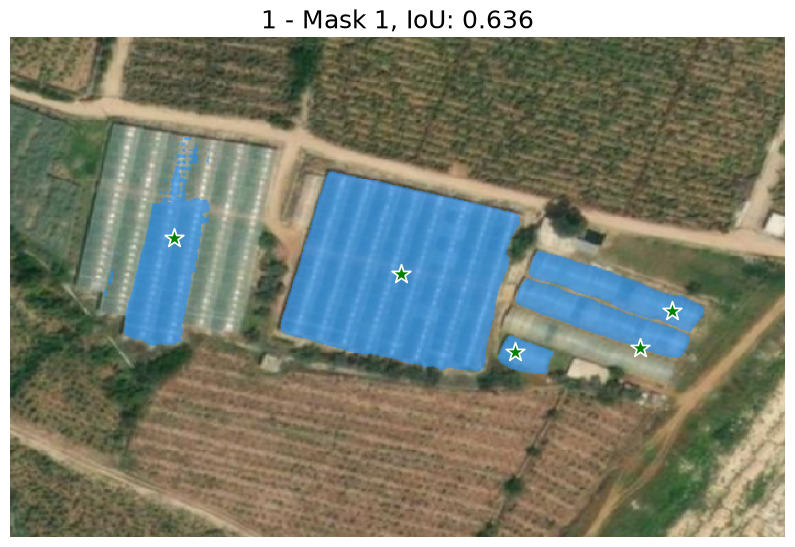

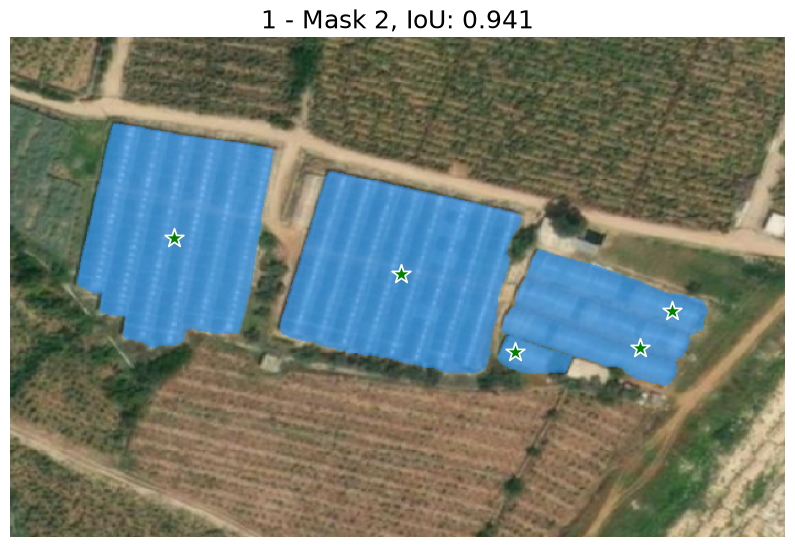

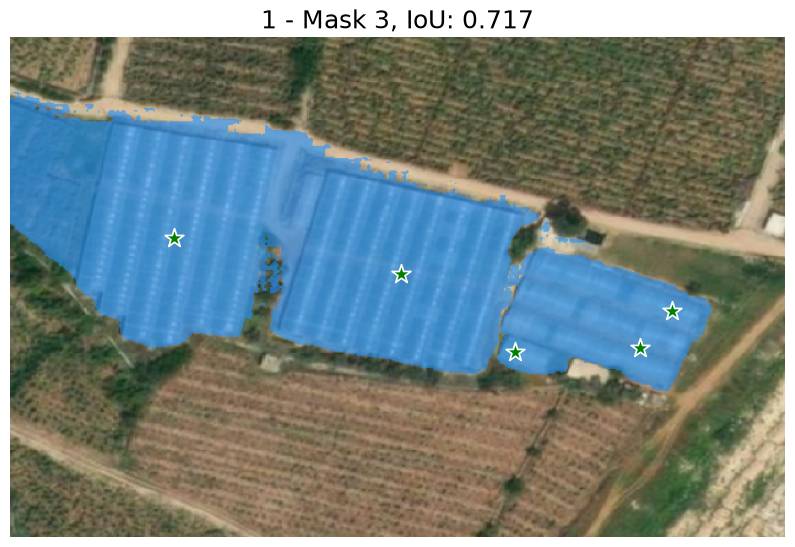

 14%|█▍        | 1/7 [00:01<00:11,  1.93s/it]

10: IoU mask1=0.151  mask2=0.778  mask3=0.676


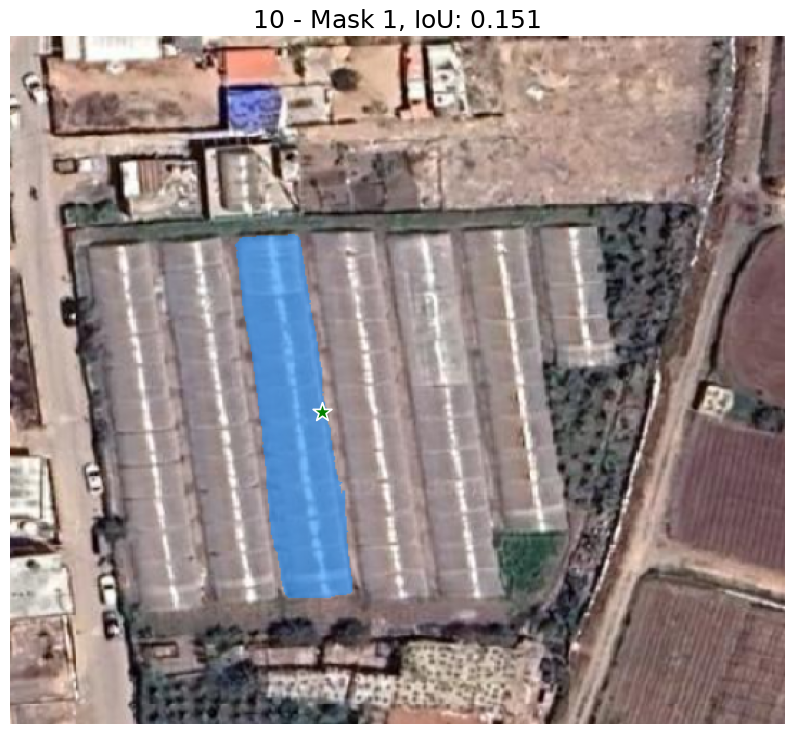

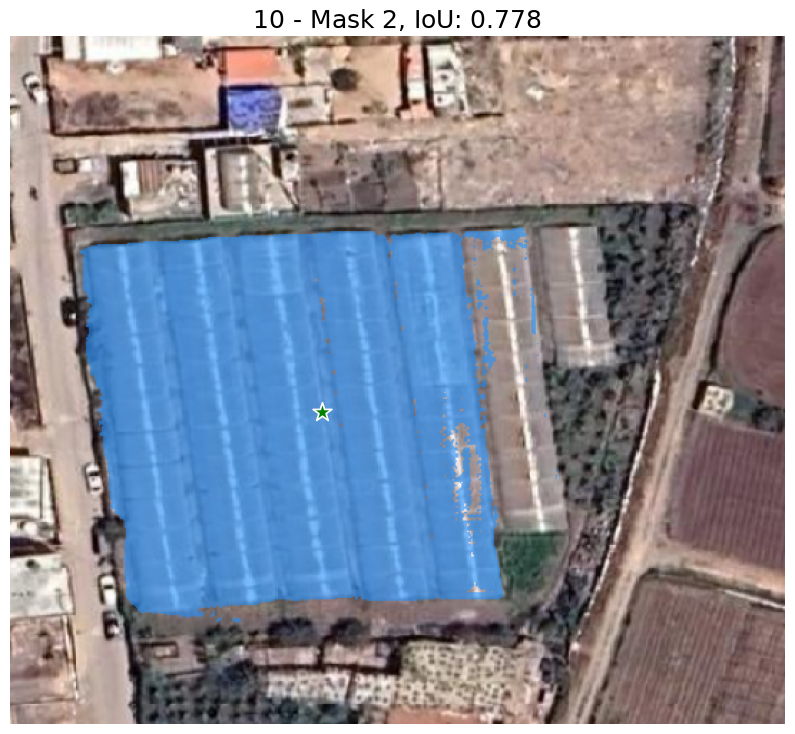

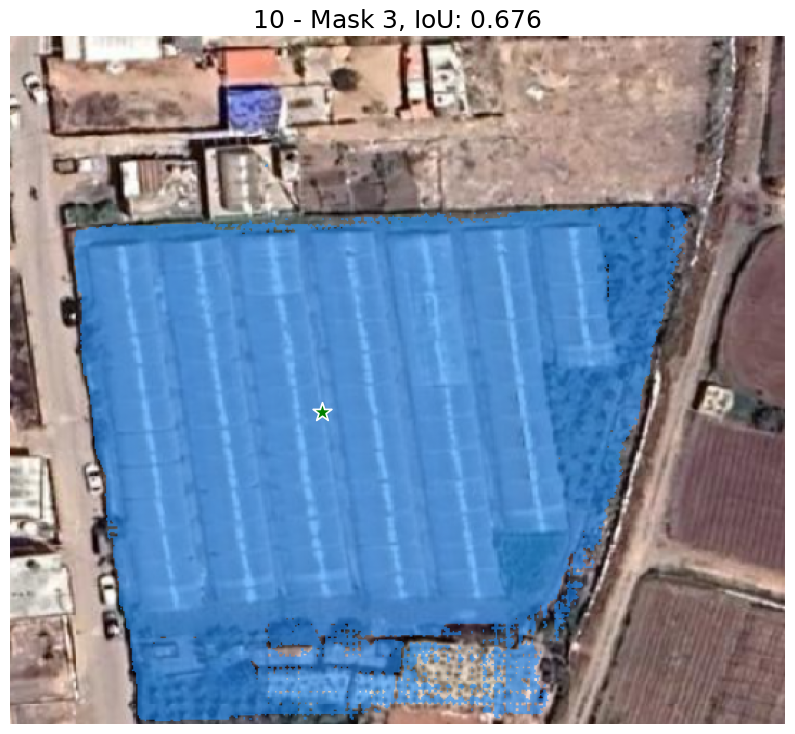

 29%|██▊       | 2/7 [00:04<00:10,  2.01s/it]

11: IoU mask1=0.019  mask2=0.161  mask3=0.933


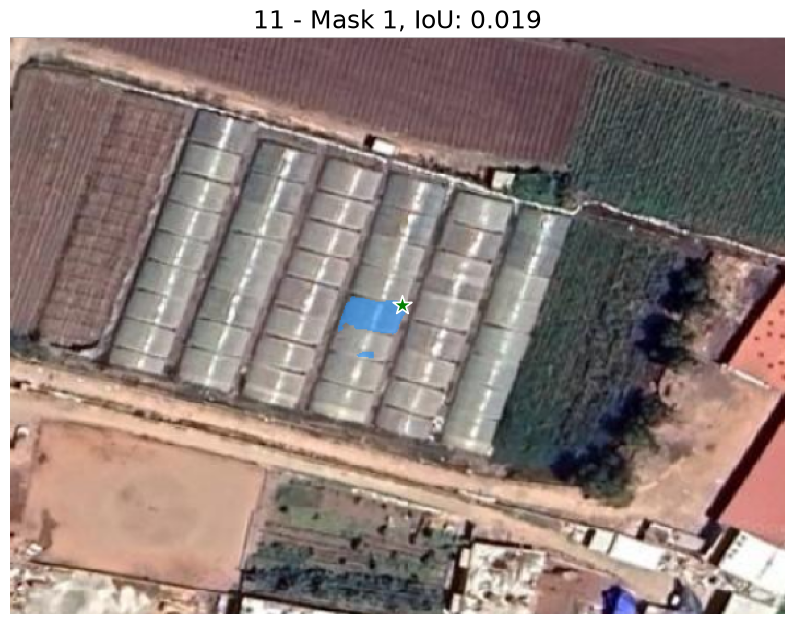

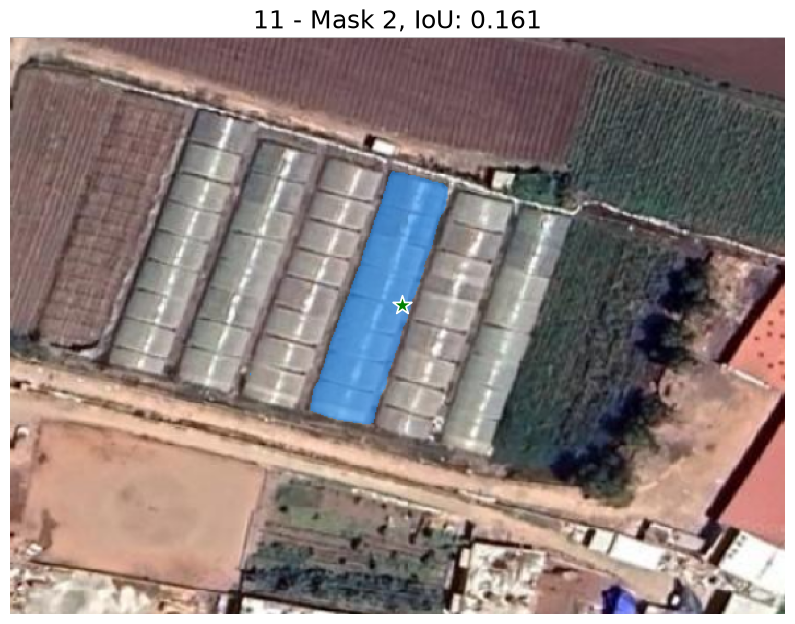

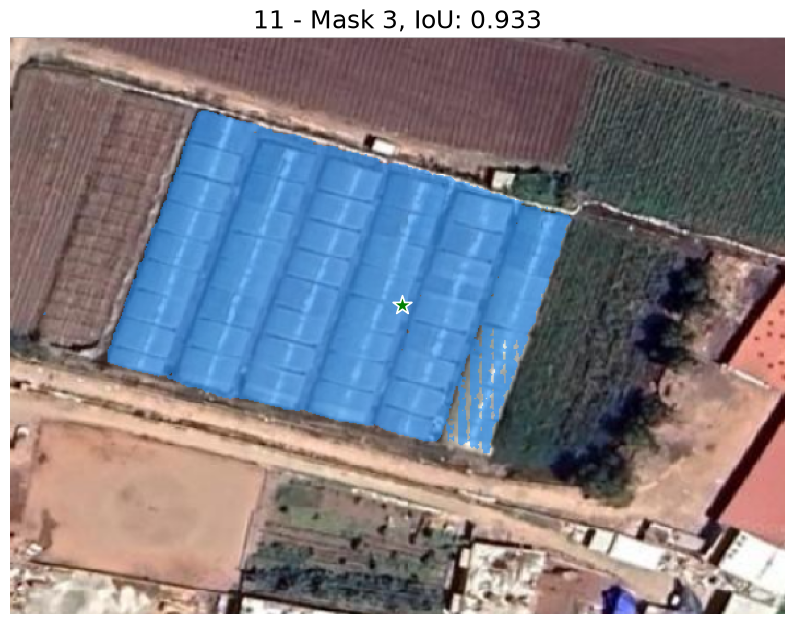

 43%|████▎     | 3/7 [00:06<00:08,  2.04s/it]

12: IoU mask1=0.898  mask2=0.820  mask3=0.448


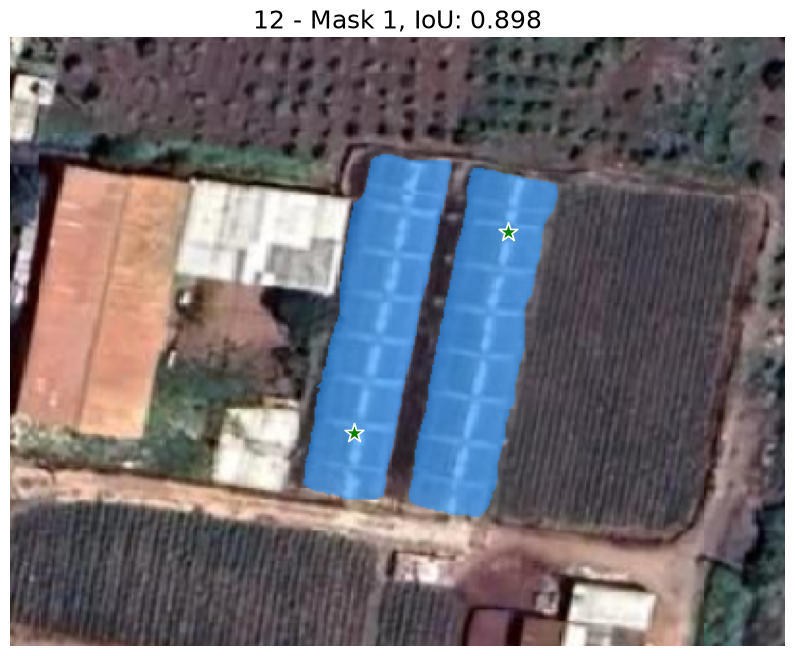

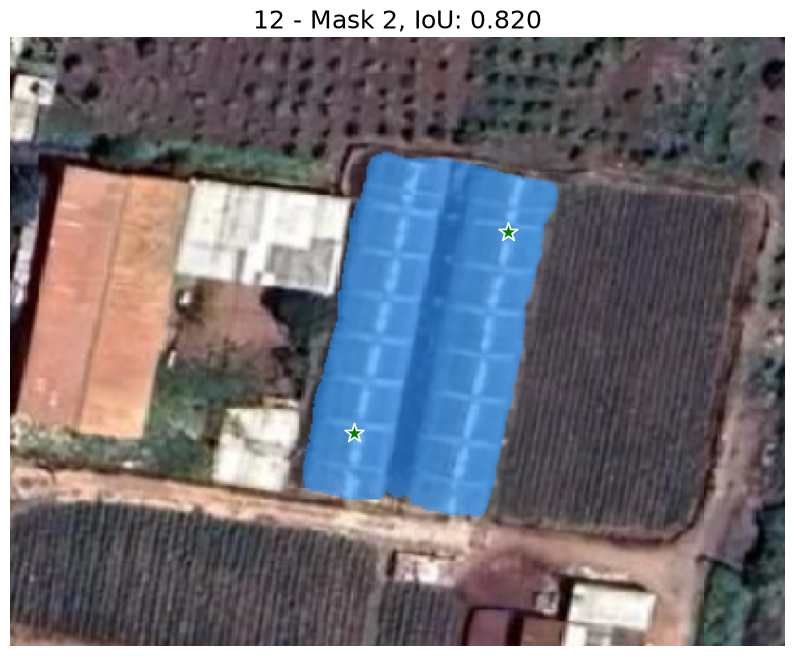

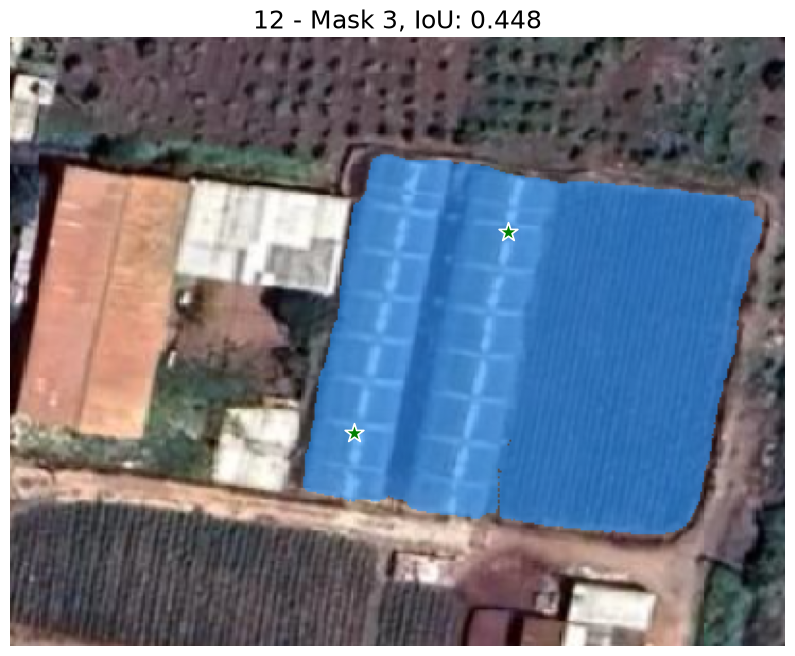

 57%|█████▋    | 4/7 [00:08<00:06,  2.07s/it]

13: IoU mask1=0.093  mask2=0.310  mask3=0.889


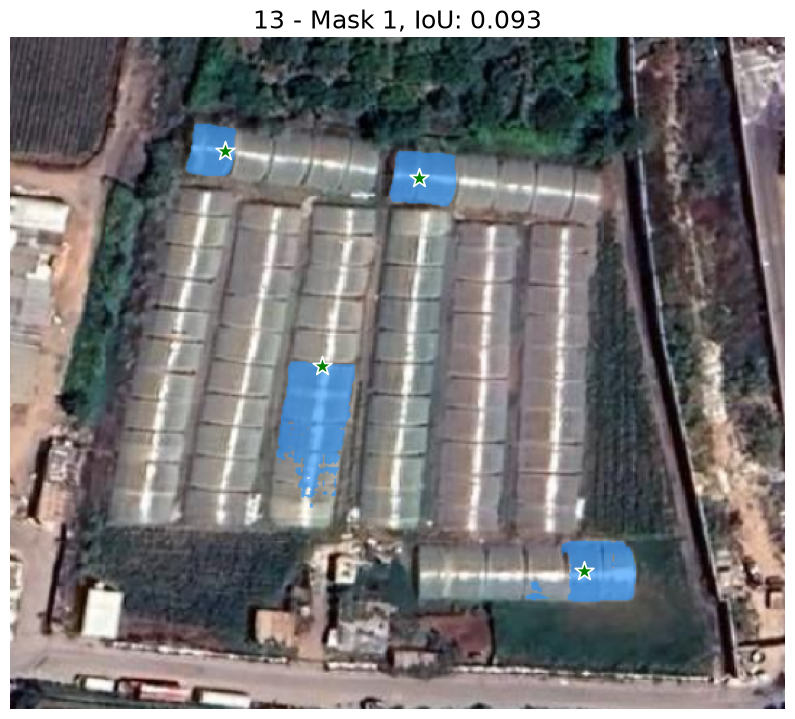

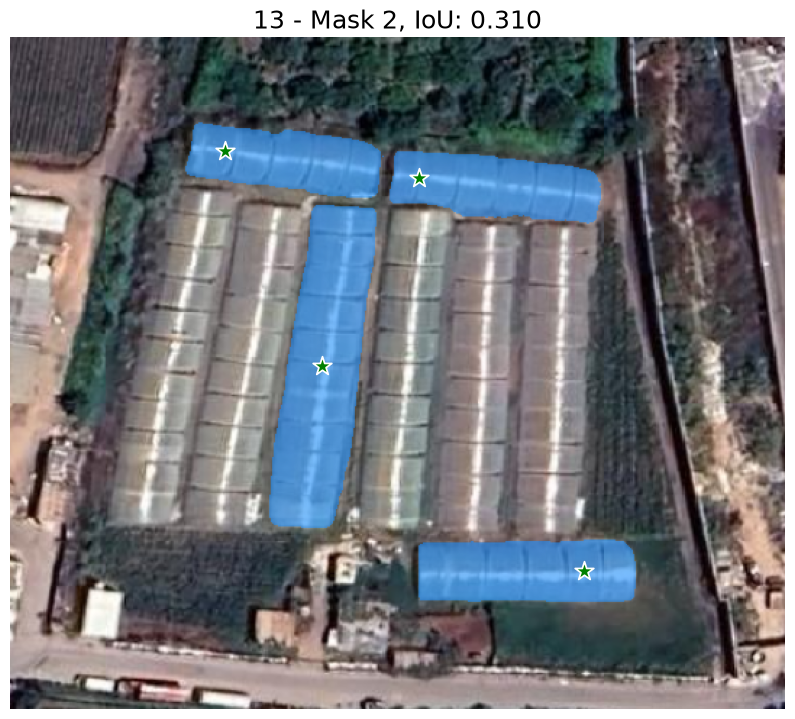

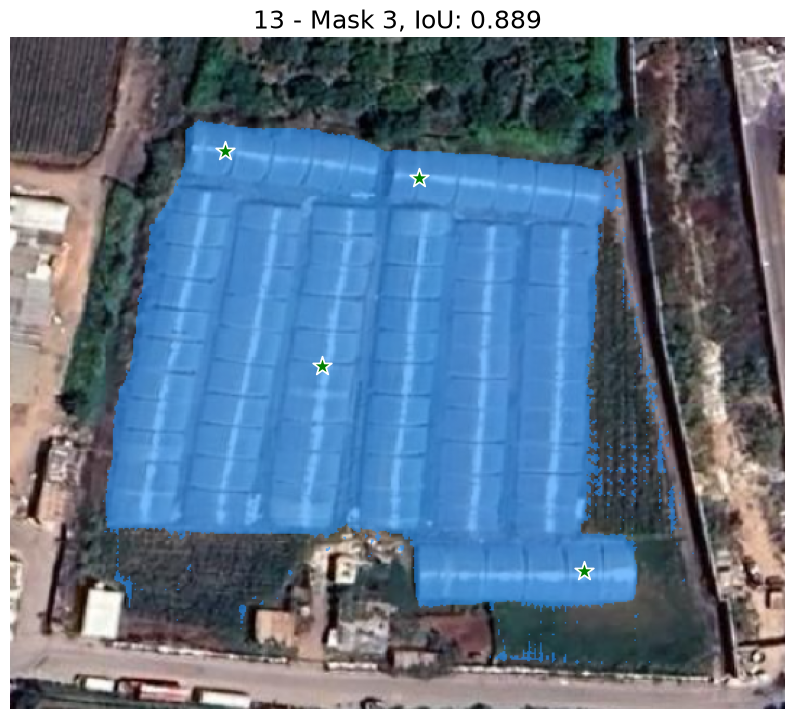

 71%|███████▏  | 5/7 [00:10<00:04,  2.08s/it]

14: IoU mask1=0.015  mask2=0.938  mask3=0.271


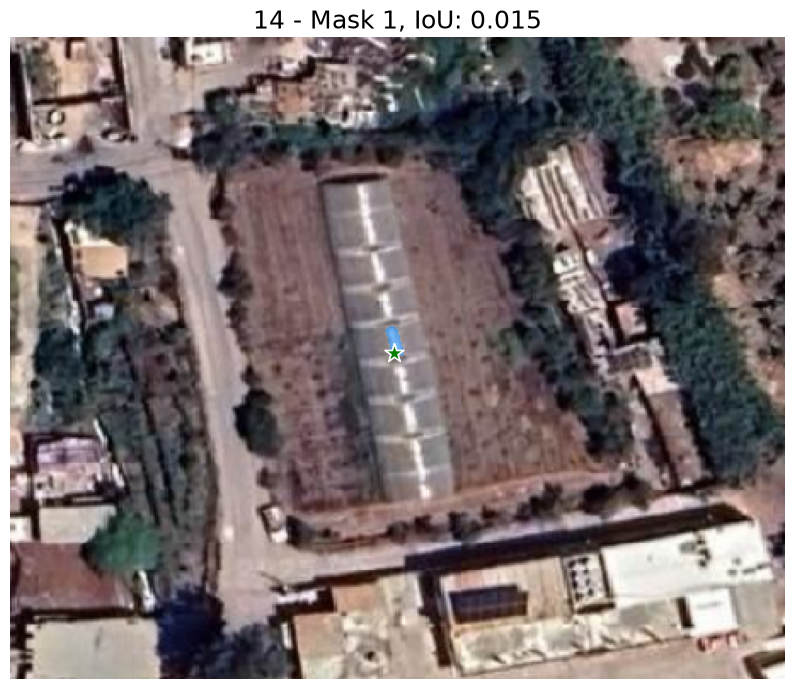

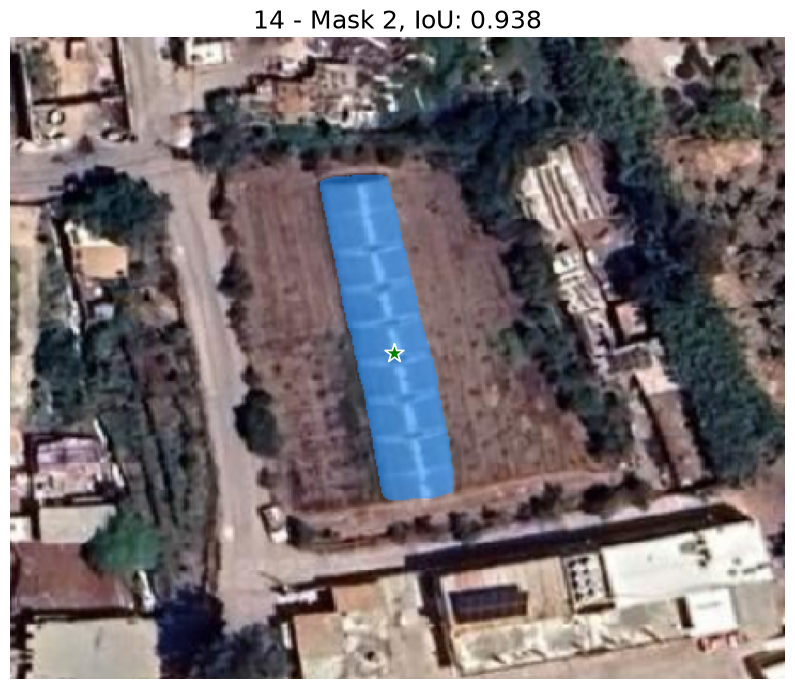

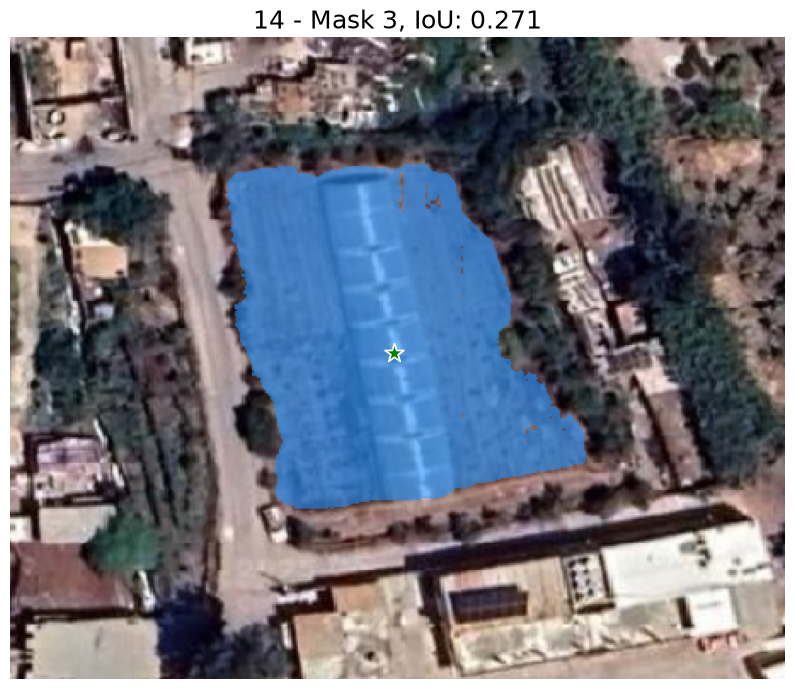

 86%|████████▌ | 6/7 [00:12<00:02,  2.09s/it]

15: IoU mask1=0.568  mask2=0.860  mask3=0.197


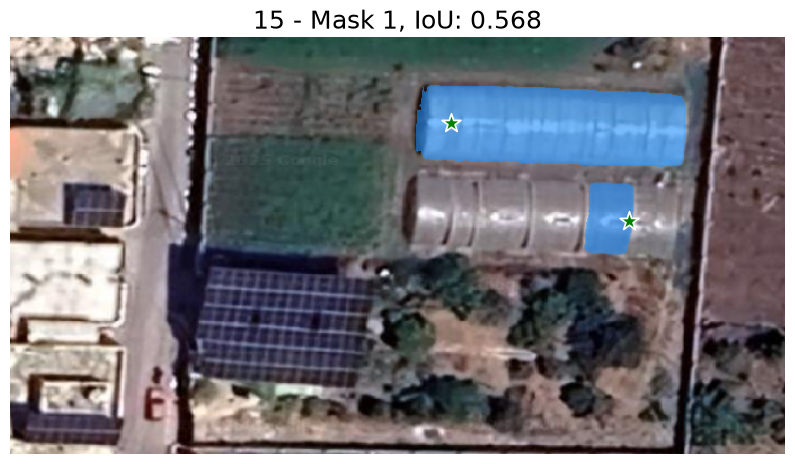

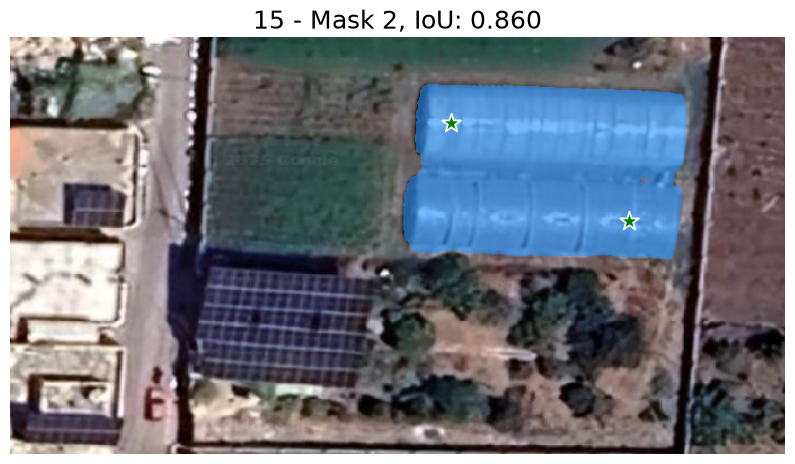

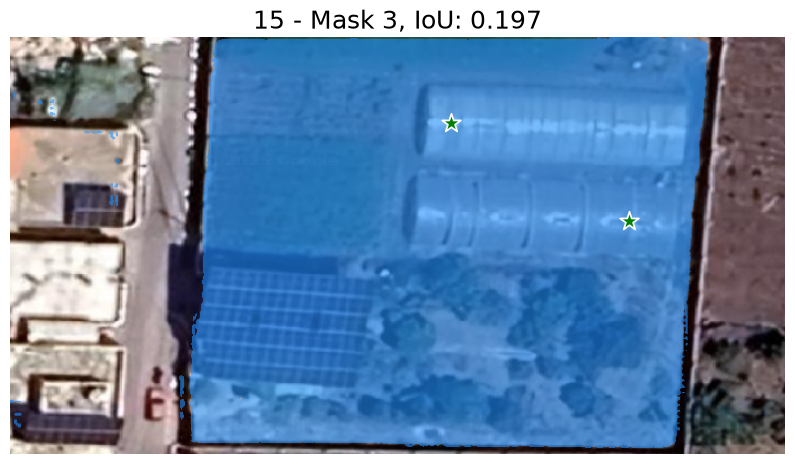

100%|██████████| 7/7 [00:14<00:00,  2.06s/it]

Mean IoU mask1: 0.340
Mean IoU mask2: 0.687
Mean IoU mask3: 0.590


In [15]:
import os
import json
import base64
from glob import glob

import numpy as np
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm

# ---------------------------------------------------------------------------
# Paths / settings
# ---------------------------------------------------------------------------
images_dir = r'C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset4\images'

# How each polygon is turned into a SAM prompt:
#   "point" -> one foreground point guaranteed to lie inside the polygon
#              (same idea as the shapefile point workflow)
#   "box"   -> the polygon's bounding box (usually gives better masks with SAM)
PROMPT_MODE = "point"

SHOW_PLOTS = True

# `predictor` must already exist, e.g.:
# from segment_anything import sam_model_registry, SamPredictor
# sam = sam_model_registry["vit_h"](checkpoint="sam_vit_h_4b8939.pth").to("cuda")
# predictor = SamPredictor(sam)


# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------
def load_labelme(json_path):
    """Return the parsed JSON and the list of polygon point lists."""
    with open(json_path, 'r') as f:
        data = json.load(f)
    polys = [
        s['points'] for s in data.get('shapes', [])
        if s.get('shape_type', 'polygon') == 'polygon' and len(s['points']) >= 3
    ]
    return data, polys


def load_image(json_path, data):
    """Load the image referenced by the JSON; fall back to the embedded imageData."""
    folder = os.path.dirname(json_path)
    candidates = []
    if data.get('imagePath'):
        candidates.append(os.path.join(folder, os.path.basename(data['imagePath'])))
    stem = os.path.splitext(os.path.basename(json_path))[0]
    candidates += [os.path.join(folder, stem + ext) for ext in ('.png', '.jpg', '.jpeg', '.tif')]

    for p in candidates:
        if os.path.exists(p):
            img = cv2.imread(p)
            if img is not None:
                return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    if data.get('imageData'):
        buf = np.frombuffer(base64.b64decode(data['imageData']), np.uint8)
        img = cv2.imdecode(buf, cv2.IMREAD_COLOR)
        if img is not None:
            return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    return None


def polygon_to_mask(points, h, w):
    """Rasterize one polygon into a binary (h, w) mask."""
    mask = np.zeros((h, w), dtype=np.uint8)
    pts = np.round(np.asarray(points, dtype=np.float32)).astype(np.int32).reshape(-1, 1, 2)
    cv2.fillPoly(mask, [pts], 1)
    return mask


def interior_point(obj_mask):
    """Point deepest inside the object (works for concave shapes, unlike the centroid)."""
    dist = cv2.distanceTransform(obj_mask, cv2.DIST_L2, 5)
    y, x = np.unravel_index(np.argmax(dist), dist.shape)
    return [float(x), float(y)]


def calculateIoU(gt, pred):
    gt = gt > 0
    pred = pred > 0
    union = np.logical_or(gt, pred).sum()
    if union == 0:
        return 1.0
    return np.logical_and(gt, pred).sum() / union


def show_mask(mask, ax, random_color=False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30 / 255, 144 / 255, 255 / 255, 0.6])
    h, w = mask.shape[-2:]
    ax.imshow(mask.reshape(h, w, 1) * color.reshape(1, 1, -1))


def show_points(coords, labels, ax, marker_size=200):
    pos = coords[labels == 1]
    neg = coords[labels == 0]
    ax.scatter(pos[:, 0], pos[:, 1], color='green', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)
    ax.scatter(neg[:, 0], neg[:, 1], color='red', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)


def show_box(box, ax):
    x0, y0, x1, y1 = box
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, edgecolor='green', facecolor=(0, 0, 0, 0), lw=2))


# ---------------------------------------------------------------------------
# Main loop
# ---------------------------------------------------------------------------
results = {}

for json_path in tqdm(sorted(glob(os.path.join(images_dir, '*.json')))):
    name = os.path.splitext(os.path.basename(json_path))[0]

    data, polys = load_labelme(json_path)
    if not polys:
        print(f"{name}: no polygons, skipped")
        continue

    image = load_image(json_path, data)
    if image is None:
        print(f"{name}: image not found, skipped")
        continue

    h, w = image.shape[:2]

    # Scale polygon coordinates if the image on disk differs from the annotated size
    sx = w / data.get('imageWidth', w)
    sy = h / data.get('imageHeight', h)
    polys = [[[x * sx, y * sy] for x, y in p] for p in polys]

    predictor.set_image(image)

    gt_m = np.zeros((h, w), dtype=bool)          # ground truth from the JSON polygons
    mask_tile = np.zeros((3, h, w), dtype=bool)  # union of SAM's 3 multimask outputs
    input_point, input_label, input_boxes = [], [], []

    for poly in polys:
        obj = polygon_to_mask(poly, h, w)
        if obj.sum() == 0:
            continue
        gt_m |= obj.astype(bool)

        if PROMPT_MODE == "box":
            pts = np.asarray(poly)
            box = np.array([pts[:, 0].min(), pts[:, 1].min(), pts[:, 0].max(), pts[:, 1].max()])
            masks, scores, logits = predictor.predict(box=box, multimask_output=True)
            input_boxes.append(box)
        else:
            pt = np.array([interior_point(obj)], dtype=np.float32)  # shape (1, 2)
            lab = np.array([1], dtype=np.int64)                     # 1 = foreground
            masks, scores, logits = predictor.predict(
                point_coords=pt,
                point_labels=lab,
                multimask_output=True,
            )
            input_point.append(pt[0])
            input_label.append(1)

        mask_tile |= np.asarray(masks, dtype=bool)  # OR instead of + so values stay 0/1

    ious = [calculateIoU(gt_m, mask_tile[k]) for k in range(3)]
    results[name] = ious
    print(f"{name}: IoU mask1={ious[0]:.3f}  mask2={ious[1]:.3f}  mask3={ious[2]:.3f}")

    if SHOW_PLOTS:
        input_point = np.array(input_point)
        input_label = np.array(input_label)
        for k, (mask, iou) in enumerate(zip(mask_tile, ious)):
            plt.figure(figsize=(10, 10))
            plt.imshow(image)
            show_mask(mask, plt.gca())
            if PROMPT_MODE == "box":
                for b in input_boxes:
                    show_box(b, plt.gca())
            elif len(input_point):
                show_points(input_point, input_label, plt.gca())
            plt.title(f"{name} - Mask {k + 1}, IoU: {iou:.3f}", fontsize=18)
            plt.axis('off')
            plt.show()

# Summary over the whole folder
if results:
    all_ious = np.array(list(results.values()))
    for k in range(3):
        print(f"Mean IoU mask{k + 1}: {all_ious[:, k].mean():.3f}")